# UK House Prices 2014–2025: Cleaning, Validation and Regional Trends

**Question:** What does twelve years of official UK house-price data say about where prices are rising fastest, how Greater Manchester compares with the rest of the country, and whether there is a "cheapest month" to buy?

**Data:** [UK House Price Index](https://www.gov.uk/government/publications/about-the-uk-house-price-index/about-the-uk-house-price-index) (HM Land Registry, Open Government Licence). It has 58,320 monthly rows covering 405 areas from January 2014 to December 2025, with average prices by property type and sales volumes.

**What this notebook covers**

1. Loading the data and preparing the core sales columns
2. A data-quality check: do new + existing sales add up to total sales?
3. Removing national aggregates and incomplete rows
4. Sales activity by region
5. The Greater Manchester price trend
6. The most expensive areas for detached houses in 2024, and where Greater Manchester ranks
7. Building a House Price Index (Jan 2015 = 100) to compare growth fairly across areas
8. Testing whether one month is reliably the cheapest to buy a flat

Tools: pandas, NumPy, matplotlib.

In [1]:
import calendar

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 11,
})
BLUE, ORANGE, GREY = "#2563eb", "#f97316", "#9ca3af"

df = pd.read_csv("data/UK_houseprices2026.csv")
print(f"{df.shape[0]:,} rows × {df.shape[1]} columns, "
      f"{df['Region'].nunique()} areas, {df['Date'].min()} to {df['Date'].max()}")
df.head()

58,320 rows × 18 columns, 405 areas, 2014-01-01 to 2025-12-01


,Date,Region,Mean Price,Sales Volume,New Price,New Sales Volume,Old Price,Old Sales Volume,Detached Price,Semi-Detached Price,Terraced Price,Flat Price,Cash Price,Cash Sales Volume,Mortgage Price,Mortgage Sales Volume,FTB Price,FOO Price
0,2014-01-01,Aberdeenshire,192239,411.0,260142.0,62.0,184548.0,349.0,276808.0,168052.0,141761.0,109450.0,179333.0,111.0,199310.0,300.0,150307.0,226869.0
1,2014-02-01,Aberdeenshire,191558,347.0,259718.0,84.0,183857.0,263.0,275641.0,167303.0,141339.0,109561.0,178732.0,79.0,198590.0,268.0,150054.0,225868.0
2,2014-03-01,Aberdeenshire,187155,383.0,253922.0,86.0,179592.0,297.0,270184.0,163266.0,137690.0,106211.0,174452.0,111.0,194095.0,272.0,146308.0,220887.0
3,2014-04-01,Aberdeenshire,189000,513.0,256803.0,100.0,181342.0,413.0,271913.0,165402.0,139679.0,107314.0,176207.0,121.0,195993.0,392.0,148189.0,222767.0
4,2014-05-01,Aberdeenshire,192885,585.0,263044.0,103.0,185020.0,482.0,277360.0,169069.0,142767.0,109078.0,179742.0,140.0,200057.0,445.0,150990.0,227513.0


`df` is treated as read-only throughout: every step below builds a new data frame from it, so each result can be reproduced independently.

## 1. Core sales data

The first eight columns hold the headline figures: date, area, mean price and sales volumes for new-build and existing homes. I also extract the mean-price series without missing values.

In [2]:
sales = df.iloc[:, :8]
avgPrice = sales["Mean Price"].dropna()

print(list(sales.columns))
print(f"Mean price available for {len(avgPrice):,} of {len(sales):,} rows")

['Date', 'Region', 'Mean Price', 'Sales Volume', 'New Price', 'New Sales Volume', 'Old Price', 'Old Sales Volume']
Mean price available for 58,320 of 58,320 rows


## 2. Data-quality check: do the sales volumes add up?

Each sale is either a new build or an existing ("old") property, so we expect

$$\text{Sales Volume} = \text{New Sales Volume} + \text{Old Sales Volume}.$$

I flag any row where the two sides differ by more than 0.5 (allowing for rounding).

In [3]:
diff = df["Sales Volume"] - (df["New Sales Volume"] + df["Old Sales Volume"])
abs_diff = diff.abs()

mismatch = abs_diff > 0.5
mismatchCount = mismatch.sum()
mismatchRegions = df.loc[mismatch, "Region"].unique()

print(f"{mismatchCount} rows don't add up, in {len(mismatchRegions)} areas:")
print(list(mismatchRegions))

75 rows don't add up, in 5 areas:
['Inner London', 'North Northamptonshire', 'Northern Ireland', 'United Kingdom', 'West Northamptonshire']


**Finding:** only 75 of 58,320 rows (0.13%) are inconsistent, and they are concentrated in five areas. Two of them, North and West Northamptonshire, are the unitary authorities created in 2021, and boundary changes are a likely cause. The rest are aggregates (Inner London, Northern Ireland, United Kingdom). The data is reliable enough to use, but these areas are worth a caveat in any sales-volume analysis.

## 3. Cleaning: remove national aggregates and incomplete rows

The `Region` column mixes geographic levels: nations, English regions, counties and local authorities all appear side by side. For an area-level view I drop the five national totals and any row with missing values.

In [4]:
remove_regions = ["United Kingdom",
                  "England",
                  "Scotland",
                  "Wales",
                  "Northern Ireland"]
filtered_regions = df[~df["Region"].isin(remove_regions)]

sales_clean = filtered_regions.dropna()
print(f"{len(sales_clean):,} complete area-level rows remain (from {len(df):,})")

52,678 complete area-level rows remain (from 58,320)


## 4. Where are homes being sold?

Total sales volume per area over the whole period:

In [5]:
soldPerRegion = df.groupby("Region")["Sales Volume"].sum()
soldPerRegion.sort_values(ascending=False).head(10)

Region
United Kingdom       11705498.0
Great Britain        11422093.0
England and Wales    10241341.0
England               9721933.0
South East            1732338.0
North West            1280455.0
Scotland              1180548.0
East of England       1178437.0
South West            1148190.0
London                1125072.0
Name: Sales Volume, dtype: float64

The top of the list is dominated by aggregates (UK, Great Britain, England and Wales). To compare like with like, I plot the 12 areas that partition the UK: England's nine regions plus Scotland, Wales and Northern Ireland.

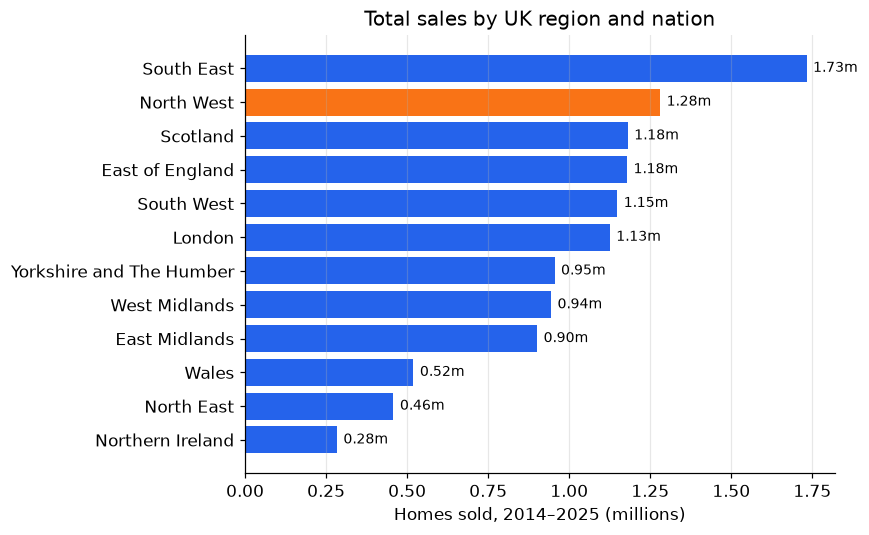

In [6]:
uk_parts = ["North East", "North West", "Yorkshire and The Humber", "East Midlands",
            "West Midlands Region", "East of England", "London", "South East", "South West",
            "Scotland", "Wales", "Northern Ireland"]
# "West Midlands" alone is the metropolitan county; the region has its own label
parts = soldPerRegion[uk_parts].rename({"West Midlands Region": "West Midlands"}).sort_values() / 1e6

fig, ax = plt.subplots(figsize=(8, 5))
colors = [ORANGE if r == "North West" else BLUE for r in parts.index]
ax.barh(parts.index, parts.values, color=colors)
ax.set_xlabel("Homes sold, 2014–2025 (millions)")
ax.set_title("Total sales by UK region and nation")
ax.grid(axis="y", visible=False)
for y, v in enumerate(parts.values):
    ax.text(v + 0.02, y, f"{v:.2f}m", va="center", fontsize=9)
plt.tight_layout()
plt.show()

The South East is the most active housing market by volume, followed by the North West, which includes Greater Manchester.

## 5. Greater Manchester: average price by year

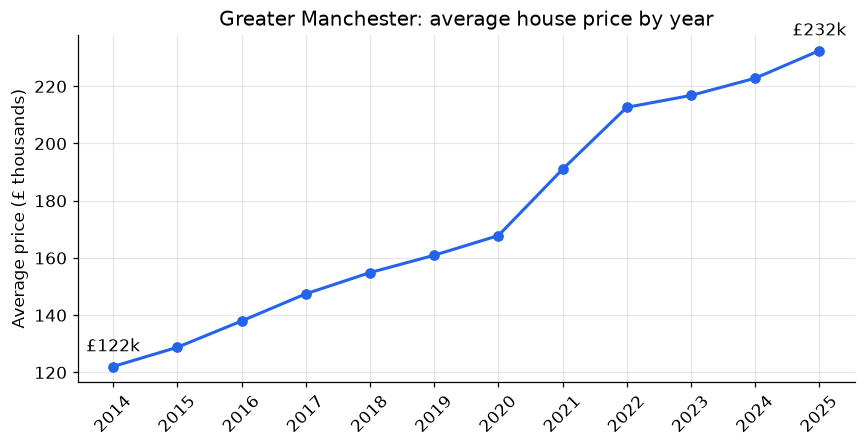

Change 2014→2025: +90%


In [7]:
GM = df[df["Region"] == "Greater Manchester"].copy()
GM["Year"] = pd.to_datetime(GM["Date"]).dt.year

annualAvg = GM.groupby("Year")["Mean Price"].mean()

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(annualAvg.index, annualAvg.values / 1000, marker="o", color=BLUE, lw=2)
ax.set_ylabel("Average price (£ thousands)")
ax.set_title("Greater Manchester: average house price by year")
ax.set_xticks(annualAvg.index)
ax.tick_params(axis="x", rotation=45)
first, last = annualAvg.iloc[0], annualAvg.iloc[-1]
ax.annotate(f"£{first/1000:.0f}k", (annualAvg.index[0], first / 1000), textcoords="offset points", xytext=(0, 10), ha="center")
ax.annotate(f"£{last/1000:.0f}k", (annualAvg.index[-1], last / 1000), textcoords="offset points", xytext=(0, 10), ha="center")
plt.tight_layout()
plt.show()

print(f"Change {annualAvg.index[0]}→{annualAvg.index[-1]}: {last / first - 1:+.0%}")

The average Greater Manchester home went from about **£122k in 2014 to £232k in 2025, up 90%**. Growth was steady until 2020, then jumped by 14% in 2021 alone, the year of the stamp-duty holiday and the post-lockdown demand spike.

## 6. The most expensive areas for detached houses (2024)

For 2024 I take each area's median detached-house price, then flag areas above the 95th percentile.

In [8]:
df_new = df.copy()
df_new["Year"] = pd.to_datetime(df["Date"]).dt.year
df2024 = df_new[df_new["Year"] == 2024]

detached2024 = df2024.groupby("Region")["Detached Price"].median()
expensive = detached2024.quantile(0.95)

detached2024_expensive = detached2024[detached2024 > expensive]
print(f"95th percentile: £{expensive:,.0f}; {len(detached2024_expensive)} areas lie above it")

95th percentile: £1,179,200; 20 areas lie above it


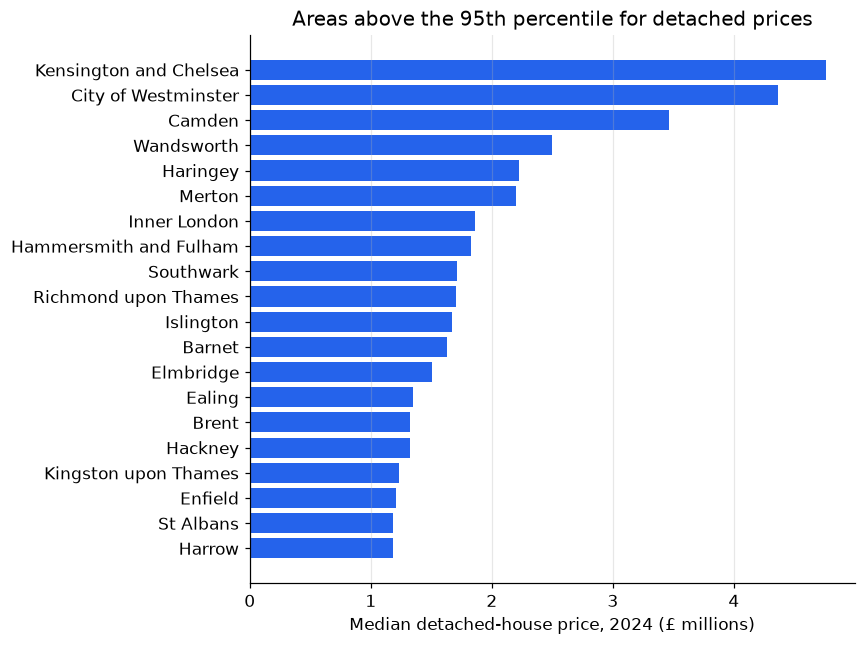

In [9]:
top = detached2024_expensive.sort_values() / 1e6

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color=BLUE)
ax.set_xlabel("Median detached-house price, 2024 (£ millions)")
ax.set_title("Areas above the 95th percentile for detached prices")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Seventeen of the 20 are London boroughs, plus the Inner London aggregate. The only two outside London, Elmbridge (Surrey) and St Albans (Hertfordshire), are commuter-belt areas next to it. Kensington and Chelsea tops the list at a median of about **£4.8m**.

### Where does Greater Manchester rank?

What is the largest percentile threshold $p$ at which Greater Manchester still counts as "expensive"? That is the share of areas whose median detached price is at or below Greater Manchester's.

In [10]:
gm_value = detached2024["Greater Manchester"]
p_gm = (detached2024 <= gm_value).mean()

print(f"Greater Manchester median detached price (2024): £{gm_value:,.0f}")
print(f"p_gm = {p_gm:.3f} → more expensive than about {p_gm:.0%} of UK areas")

Greater Manchester median detached price (2024): £390,556
p_gm = 0.402 → more expensive than about 40% of UK areas


For detached homes, Greater Manchester sits around the **40th percentile**, below the UK middle.

## 7. A House Price Index: who has grown fastest?

Raw prices make London look like the strongest market, but a £50k rise means very different things on a £150k and a £700k home. To compare *growth*, I rescale each area's mean price so that **January 2015 = 100**, the same approach the official UK HPI uses.

In [11]:
df_hpi = df.copy()
df_hpi["Date"] = pd.to_datetime(df_hpi["Date"])

base = df_hpi[(df_hpi["Date"].dt.year == 2015) & (df_hpi["Date"].dt.month == 1)]
base_prices = base.set_index("Region")["Mean Price"]

df_hpi["HPI"] = (df_hpi["Mean Price"] / df_hpi["Region"].map(base_prices))*100

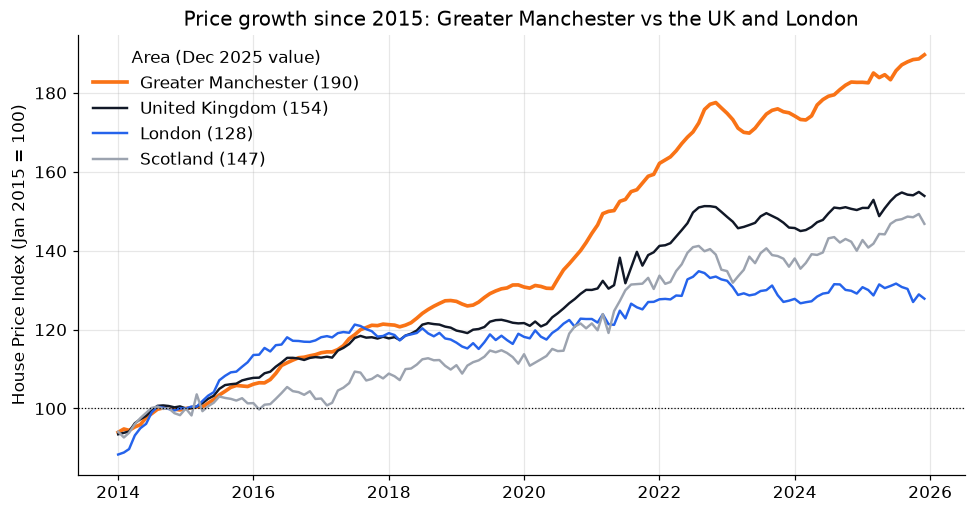

In [12]:
show = {"Greater Manchester": ORANGE, "United Kingdom": "#111827", "London": BLUE, "Scotland": GREY}

fig, ax = plt.subplots(figsize=(9, 4.8))
for region, color in show.items():
    s = df_hpi[df_hpi["Region"] == region].set_index("Date")["HPI"]
    ax.plot(s.index, s.values, label=f"{region} ({s.iloc[-1]:.0f})", color=color,
            lw=2.4 if region == "Greater Manchester" else 1.6)
ax.axhline(100, color="black", lw=0.8, ls=":")
ax.set_ylabel("House Price Index (Jan 2015 = 100)")
ax.set_title("Price growth since 2015: Greater Manchester vs the UK and London")
ax.legend(title="Area (Dec 2025 value)", frameon=False)
plt.tight_layout()
plt.show()

In [13]:
latest = df_hpi[df_hpi["Date"] == df_hpi["Date"].max()].set_index("Region")["HPI"]
latest.sort_values(ascending=False).head(10).round(1).rename("HPI, Dec 2025")

Region
Causeway Coast and Glens    211.4
Fermanagh and Omagh         205.1
Newry Mourne and Down       203.6
Salford                     202.3
Oldham                      201.1
Manchester                  199.9
Rochdale                    197.1
Derry City and Strabane     195.8
Bolsover                    192.5
Orkney Islands              192.1
Name: HPI, Dec 2025, dtype: float64

Indexing changes the picture. Since January 2015:

- **Greater Manchester: +90%**, against **+54% for the UK** and only **+28% for London**.
- Four Greater Manchester boroughs, **Salford, Oldham, Manchester and Rochdale**, are among the ten fastest-growing areas in the whole UK. Northern Irish council areas make up much of the rest.

## 8. Is there a cheapest month to buy a flat?

For every (area, year) pair I find the month with the lowest flat price, taking the earlier month if there is a tie. Then I count which month wins most often.

In [14]:
df_hpi["Date"] = pd.to_datetime(df_hpi["Date"])
df_hpi["Year"] = df_hpi["Date"].dt.year
df_hpi["Month"] = df_hpi["Date"].dt.month

# skip rows without a flat price so (area, year) groups with no data are ignored
cheap = df_hpi.dropna(subset=["Flat Price"]).groupby(["Region", "Year"])["Flat Price"].idxmin()
cheap = cheap.astype(int)
cheapest_months = df_hpi["Month"].iloc[cheap.values]
cheapest_month = cheapest_months.value_counts().idxmax()

print(f"Most frequent cheapest month: {cheapest_month}")

Most frequent cheapest month: 1


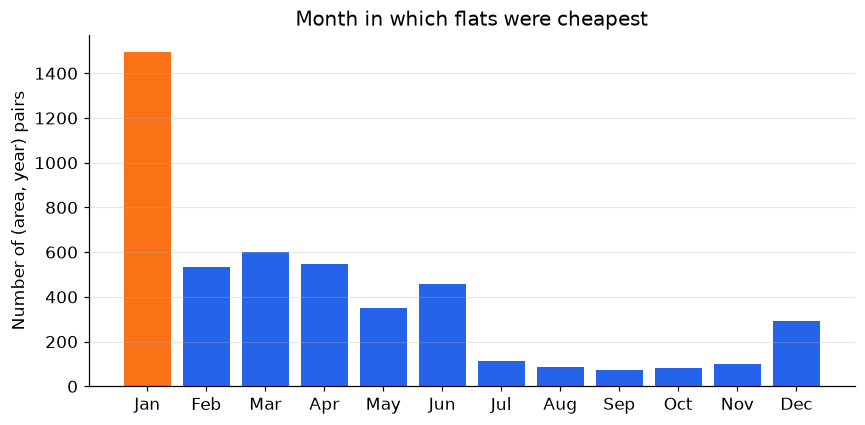

January is the cheapest month in 32% of area-years


In [15]:
counts = cheapest_months.value_counts().sort_index()
labels = [calendar.month_abbr[m] for m in counts.index]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(labels, counts.values, color=[ORANGE if m == cheapest_month else BLUE for m in counts.index])
ax.set_ylabel("Number of (area, year) pairs")
ax.set_title("Month in which flats were cheapest")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

print(f"January is the cheapest month in {counts[1] / counts.sum():.0%} of area-years")

January wins by a wide margin, in about 32% of area-years against the 8% you would expect by chance. **Caveat:** this is partly a trend effect, not just seasonality. When prices rise through the year, the earliest month is naturally the cheapest. A cleaner test would detrend each series first, for example by comparing each month with that year's average. Even so, December also ranks well above the summer and autumn months. That points to a real winter dip on top of the trend.

## Key takeaways

| | |
|---|---|
| **Data quality** | 99.9% of rows are internally consistent. The 75 exceptions cluster in 5 areas, including the post-2021 Northamptonshire authorities |
| **Greater Manchester** | Average price up 90% (2014 → 2025), with the sharpest jump in 2021 |
| **Relative growth** | Since 2015 GM grew +90%, against +54% for the UK and +28% for London. four GM boroughs are in the national top 10 |
| **Affordability** | GM's 2024 median detached price sits at about the 40th percentile of UK areas. The top 5% are almost all London |
| **Timing** | Flats are most often cheapest in January (32% of area-years), though part of that comes from the upward price trend |